# Prediksi Biaya Asuransi Kesehatan dengan Regresi Linear

**Mata Kuliah:** Machine Learning — Praktikum Regresi

**Dataset:** Medical Cost Personal Dataset (Kaggle: mirichoi0218/insurance) — file `insurance.csv`

**Target:** memprediksi `charges` (biaya asuransi, USD) dari `age, sex, bmi, children, smoker, region`.

Di Google Colab: unggah file `insurance.csv` ke folder kerja, lalu jalankan sel dari atas ke bawah.

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


## 1. Memuat dan Memeriksa Dataset

In [22]:
df = pd.read_csv('../data/insurance.csv')
print(df.shape)
df.head()

(1338, 7)


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [10]:
print('Missing value:', df.isna().sum().sum())
print('Duplikat:', df.duplicated().sum())
df.describe()

Missing value: 0
Duplikat: 1


,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


## 2. Eksplorasi Data (EDA)

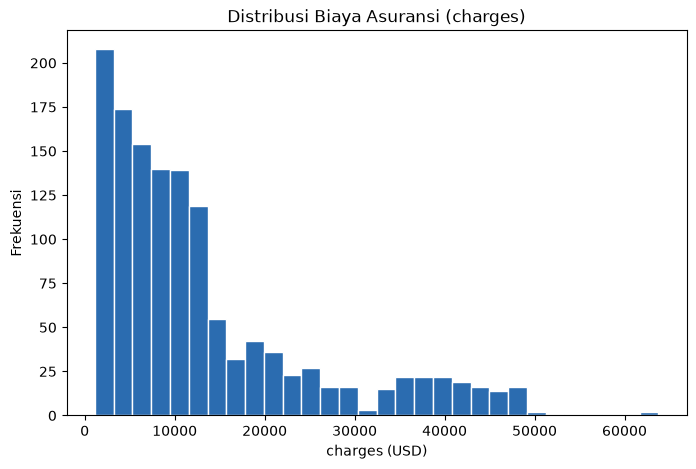

In [11]:
plt.figure(figsize=(8,5))
plt.hist(df['charges'], bins=30, color='#2b6cb0', edgecolor='white')
plt.title('Distribusi Biaya Asuransi (charges)')
plt.xlabel('charges (USD)'); plt.ylabel('Frekuensi')
plt.show()

In [12]:
df.groupby('smoker')['charges'].agg(['count','mean','median'])

,count,mean,median
smoker,,,
no,1064,8434.268298,7345.40530
yes,274,32050.231832,34456.34845


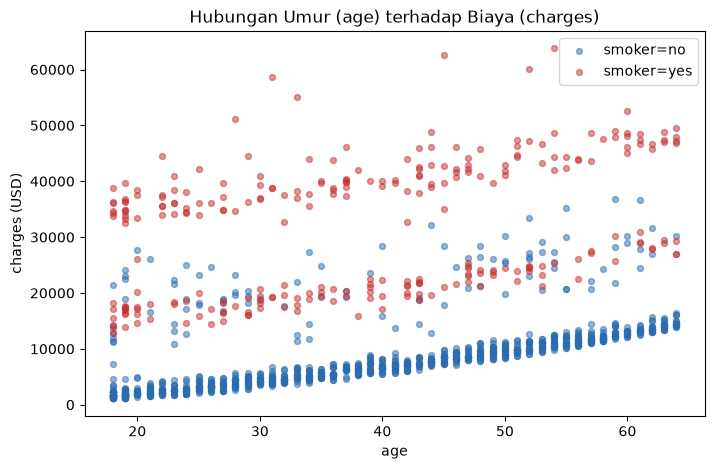

In [13]:
plt.figure(figsize=(8,5))
for label, color in [('no','#2b6cb0'), ('yes','#c53030')]:
    sub = df[df.smoker==label]
    plt.scatter(sub['age'], sub['charges'], alpha=0.5, s=18, label=f'smoker={label}', color=color)
plt.title('Hubungan Umur (age) terhadap Biaya (charges)')
plt.xlabel('age'); plt.ylabel('charges (USD)'); plt.legend(); plt.show()

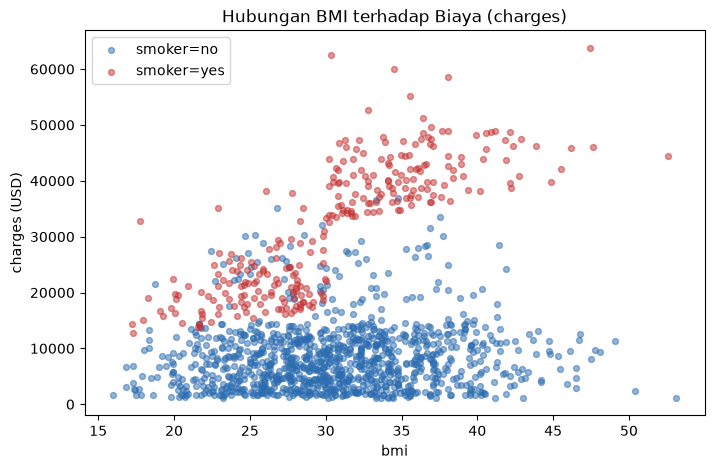

In [14]:
plt.figure(figsize=(8,5))
for label, color in [('no','#2b6cb0'), ('yes','#c53030')]:
    sub = df[df.smoker==label]
    plt.scatter(sub['bmi'], sub['charges'], alpha=0.5, s=18, label=f'smoker={label}', color=color)
plt.title('Hubungan BMI terhadap Biaya (charges)')
plt.xlabel('bmi'); plt.ylabel('charges (USD)'); plt.legend(); plt.show()

## 3. Pra-pemrosesan
- Hapus baris duplikat
- One-hot encoding (`sex`, `smoker`, `region`) dengan `drop_first=True`
- Split data latih/uji 80/20, `random_state=42`

In [15]:
df = df.drop_duplicates().reset_index(drop=True)
df_enc = pd.get_dummies(df, columns=['sex','smoker','region'], drop_first=True, dtype=float)
X = df_enc.drop(columns=['charges']); y = df_enc['charges']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print('Train:', X_train.shape, ' Test:', X_test.shape)
print(list(X.columns))

Train: (1069, 8)  Test: (268, 8)
['age', 'bmi', 'children', 'sex_male', 'smoker_yes', 'region_northwest', 'region_southeast', 'region_southwest']


## 4. Pembangunan Model Regresi Linear

In [16]:
model = LinearRegression()
model.fit(X_train, y_train)
print('Intercept:', model.intercept_)
coef = pd.Series(model.coef_, index=X.columns).sort_values(key=abs, ascending=False)
coef

Intercept: -11092.65229594595


smoker_yes          23077.764593
region_southeast     -838.919616
region_southwest     -659.139752
children              533.009989
region_northwest     -391.761455
bmi                   318.701441
age                   248.210720
sex_male             -101.542054
dtype: float64

## 5. Evaluasi Model

In [17]:
y_pred = model.predict(X_test)
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)
print(f'MAE  : {mae:,.2f}')
print(f'RMSE : {rmse:,.2f}')
print(f'R2   : {r2:.4f}')

MAE  : 4,177.05
RMSE : 5,956.34
R2   : 0.8069


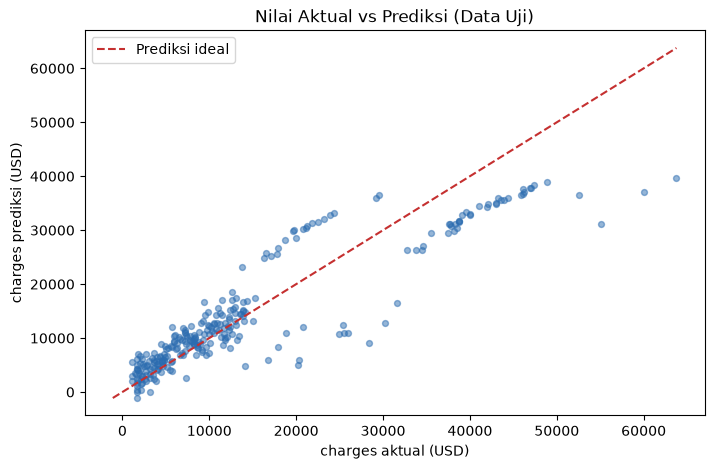

In [18]:
plt.figure(figsize=(8,5))
plt.scatter(y_test, y_pred, alpha=0.5, s=18, color='#2b6cb0')
lims=[min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
plt.plot(lims, lims, color='#c53030', linestyle='--', label='Prediksi ideal')
plt.title('Nilai Aktual vs Prediksi (Data Uji)')
plt.xlabel('charges aktual (USD)'); plt.ylabel('charges prediksi (USD)'); plt.legend(); plt.show()

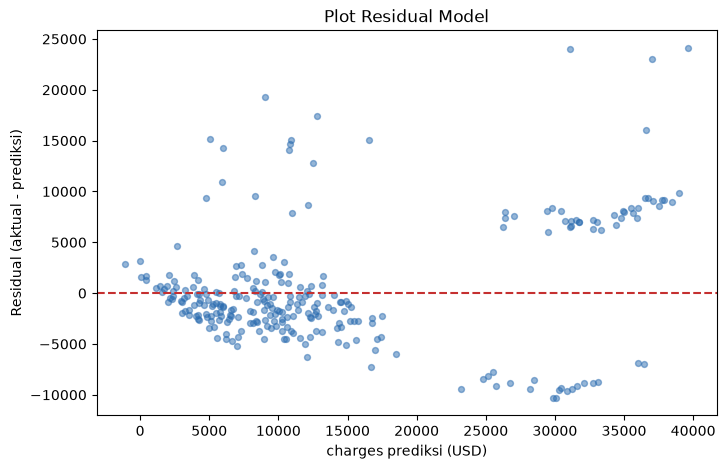

In [19]:
resid = y_test - y_pred
plt.figure(figsize=(8,5))
plt.scatter(y_pred, resid, alpha=0.5, s=18, color='#2b6cb0')
plt.axhline(0, color='#c53030', linestyle='--')
plt.title('Plot Residual Model')
plt.xlabel('charges prediksi (USD)'); plt.ylabel('Residual (aktual - prediksi)'); plt.show()

## 6. Contoh Prediksi Data Baru
Peserta laki-laki, 40 tahun, BMI 30,5, 2 anak, non-perokok, region southeast.

In [21]:
contoh = pd.DataFrame([{'age':47, 'bmi':30.5, 'children':5, 'sex_male':1.0, 'smoker_yes':0.0,
                        'region_northwest':0.0, 'region_southeast':1.0, 'region_southwest':0.0}])
contoh = contoh.reindex(columns=X.columns, fill_value=0.0)
print('Prediksi charges (USD):', round(float(model.predict(contoh)[0]), 2))

Prediksi charges (USD): 12018.23


## Kesimpulan
- Status merokok adalah faktor paling dominan terhadap biaya asuransi, diikuti umur dan BMI.
- Pada run referensi (split 80/20, random_state=42) model regresi linear memperoleh R2 = 0,8069, MAE = 4.177,05, dan RMSE = 5.956,34 pada data uji.
- Residual melebar pada biaya tinggi: pengembangan lanjutan dapat memakai interaksi `bmi x smoker` atau model non-linear.